In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d

In [2]:
x0 = 0
y0 = 0
z0 = 0
vx0 = 1
vy0 = 0
vz0 = 0.3
q = 1
m = 1
B = 1
omega = q*B/m

In [3]:
N = 200
dt = 0.1 / omega
trange = np.arange(N) * dt
vx_an = np.cos(omega*trange)
vy_an = -np.sin(omega*trange)
x_an = np.sin(omega*trange)/omega
y_an = np.cos(omega*trange)/omega - 1/omega
z_an = vz0 * trange

Text(0.5, 0, 'z')

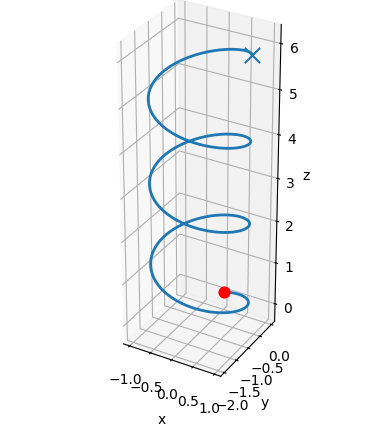

In [4]:
ax = plt.figure().add_subplot(projection='3d')
ax.plot(x_an, y_an, z_an, linewidth=2)

ax.scatter(x_an[0],  y_an[0],  z_an[0],  color="red",  s=60, marker="o", label="first")
ax.scatter(x_an[-1], y_an[-1], z_an[-1], color="C0", s=120, marker="x", label="last")

ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

In [5]:
x_eu = np.zeros(N)
y_eu = np.zeros(N)
z_eu = np.zeros(N)
vx_eu = np.zeros(N)
vy_eu = np.zeros(N)
vz_eu = np.zeros(N)
vx_eu[0] = vx0
vy_eu[0] = vy0
vz_eu[0] = vz0

In [6]:
for it in range(1,N):
    vx_eu[it] = vx_eu[it-1] + omega*dt*vy_eu[it-1]
    vy_eu[it] = vy_eu[it-1] - omega*dt*vx_eu[it-1]
    vz_eu[it] = vz_eu[it-1]
    x_eu[it] = x_eu[it-1] + vx_eu[it-1]*dt
    y_eu[it] = y_eu[it-1] + vy_eu[it-1]*dt
    z_eu[it] = z_eu[it-1] + vz_eu[it-1]*dt

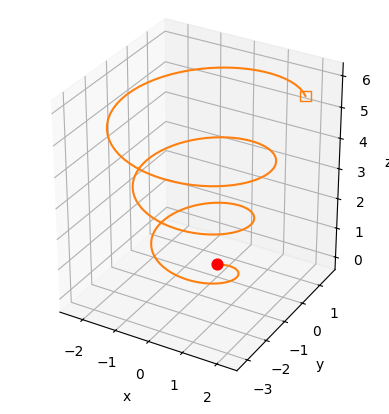

In [7]:
ax = plt.figure().add_subplot(projection='3d')
ax.plot(x_eu,y_eu,z_eu,color="C1")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.scatter(x_eu[0],  y_eu[0],  z_eu[0],  color="red",  s=60, marker="o", label="first")
ax.scatter(x_eu[-1], y_eu[-1], z_eu[-1], color="C1", s=60, marker="s", label="last",facecolors="none")

Text(0.5, 1.0, '$E_k=mv^2/2$')

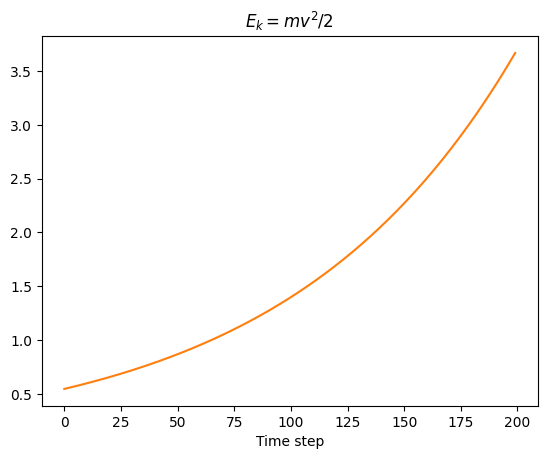

In [8]:
plt.plot(0.5*(vx_eu**2+vy_eu**2+vz_eu**2),color="C1");
plt.xlabel("Time step")
plt.title(r"$E_k=mv^2/2$")

In [9]:
N = 50
dt = 0.4 / omega
trange = np.arange(N) * dt
vx_an = np.cos(omega*trange)
vy_an = -np.sin(omega*trange)
x_an = np.sin(omega*trange)/omega
y_an = np.cos(omega*trange)/omega - 1/omega
z_an = vz0 * trange

In [10]:
x_sym = np.zeros(N)
y_sym = np.zeros(N)
z_sym = np.zeros(N)
vx_sym = np.zeros(N)
vy_sym = np.zeros(N)
vz_sym = np.zeros(N)
vx_sym[0] = vx0
vy_sym[0] = vy0
vz_sym[0] = vz0

In [11]:
def sym_push(r1,r2,r3,v1,v2,v3, a,dt):
    D = 1+a**2
    r1new = r1 + dt/2*(v1 + (1-a**2)/D*v1 + 2*a/D*v2)
    r2new = r2 + dt/2*(v2 + -a*2/D*v1 + (1-a**2)/D*v2)
    r3new = r3 + dt/2*(v3 + v3)
    v1new = (1-a**2)/D * v1 + 2*a/D * v2
    v2new = -2*a/D * v1 + (1-a**2)/D * v2
    v3new = v3
    return r1new, r2new, r3new, v1new, v2new, v3new 

In [12]:
a = dt/2*omega
for it in range(1, N):
    x_sym[it], y_sym[it], z_sym[it], vx_sym[it], vy_sym[it], vz_sym[it] = sym_push(
        x_sym[it-1], y_sym[it-1],z_sym[it-1], vx_sym[it-1], vy_sym[it-1], vz_sym[it-1],
        a, dt
    )

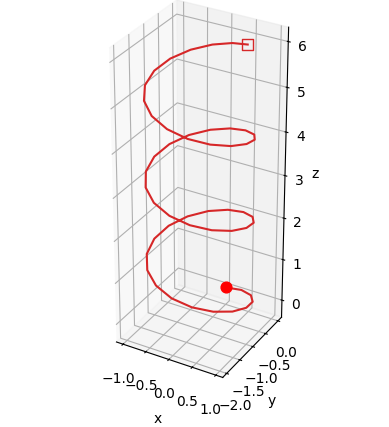

In [13]:
ax = plt.figure().add_subplot(projection='3d')
ax.plot(x_sym,y_sym,z_sym,color="C3")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.scatter(x_sym[0],  y_sym[0],  z_sym[0],  color="red",  s=60, marker="o", label="first")
ax.scatter(x_sym[-1], y_sym[-1], z_sym[-1], color="C3", s=60, marker="s", label="last",facecolors='none')

In [14]:
import time
from matplotlib import animation

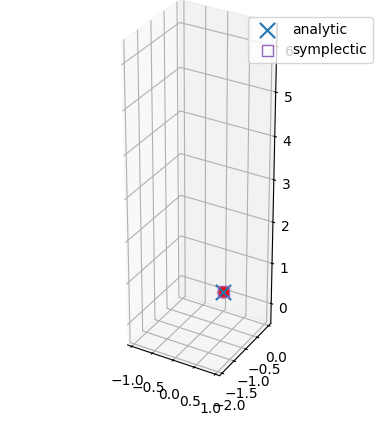

In [15]:
FRAMES = N
FPS = 12
fig = plt.figure()
ax = fig.add_subplot(projection="3d")

ax.set_xlim([-1.1,1.1])
ax.set_ylim([-2.1,0.1])
ax.set_zlim([-0.5,6.5])
ax.set_aspect("equal")

line_an = None
line_sym = None
h_an = None
h_sym = None
tstart = time.time()
ax.scatter(x_sym[0],  y_sym[0],  z_sym[0],  color="red",  s=60, marker="o")
i = 0
h_an = ax.scatter(x_an[i],  y_an[i],  z_an[i],  color="C0",  s=120, marker="x",zorder=7, label="analytic")
h_sym = ax.scatter(x_sym[i],  y_sym[i],  z_sym[i],  color="C4",  s=60, marker="s", facecolor="none",zorder=6, label="symplectic")
plt.legend()
def animate(i):
    global line_an,line_sym, h_an, h_sym
    for artist in (line_an, line_sym, h_an, h_sym):
        if artist:
            artist.remove()

    line_an = ax.plot(x_an[0:i],y_an[0:i],z_an[0:i], color="C0",linewidth=5)[0]
    line_sym = ax.plot(x_sym[0:i],y_sym[0:i],z_sym[0:i],color="C4")[0]
    h_an = ax.scatter(x_an[i],  y_an[i],  z_an[i],  color="C0",  s=120, marker="x",zorder=7)
    h_sym = ax.scatter(x_sym[i],  y_sym[i],  z_sym[i],  color="C4",  s=60, marker="s", facecolor="none",zorder=6)


    if i == FRAMES - 1:
        global tstart
        fps = FRAMES / (time.time() - tstart)
        print(f'Expected FPS: {FPS}; Average FPS: {fps}')
        tstart = time.time()

ani = animation.FuncAnimation(fig, animate, interval=1000 / FPS, frames=FRAMES)
plt.show()

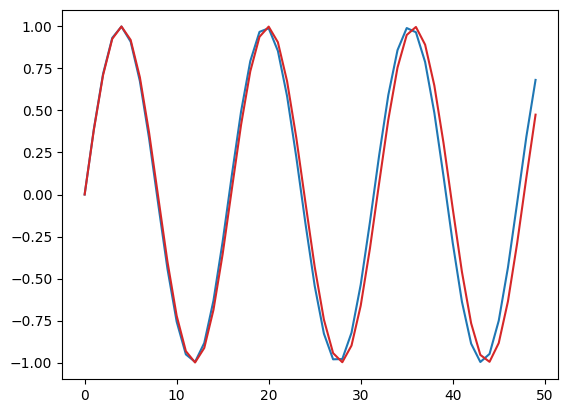

In [16]:
plt.plot(x_an)
plt.plot(x_sym,color="C3")

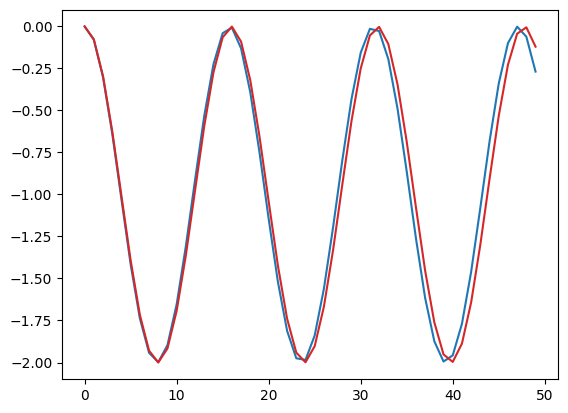

In [17]:
plt.plot(y_an)
plt.plot(y_sym,color="C3")

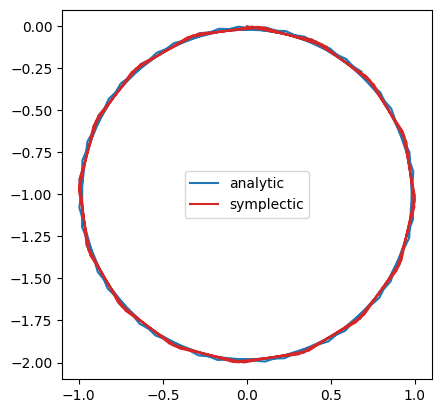

In [18]:
fig, ax = plt.subplots()
ax.plot(x_an,y_an)
ax.plot(x_sym, y_sym,color="C3")
ax.set_aspect("equal")
plt.legend(["analytic","symplectic"])